# Exerciţiu laborator 6
## Inferenţă Bayesiană

O companie de telecomunicaţii doreşte să estimeze rata medie de apeluri primite de un call center într-o oră. Din datele istorice, compania ştie că rata medie de apeluri pe oră variază în funcţie de perioadele zilei şi de anumite zile din săptămână. Într-o anumită perioadă, managerul observă că, timp de 10 ore, au fost primite un total de 180 de apeluri. Să notăm cu $\lambda$ rata medie de apeluri pe oră. Având în vedere că numărul de apeluri pe oră poate fi modelat ca o variabilă Poisson, avem următoarele informaţii:

● Datele observate: În 10 ore, au fost primite 180 de apeluri, ceea ce oferă o rată medie observată de 18 apeluri pe oră. \
● Distribuţia verosimilităţii: Presupunem că numărul de apeluri pe oră urmează o distribuţie Poisson cu parametru $\lambda$.

Alegând o distribuţie Gamma ca distribuţie a priori pentru $\lambda$ (deoarece este conjugata a priori a distribuţiei Poisson), determinaţi distribuţia a posteriori, un interval HDI de 94% şi cea mai probabilă valoare a lui $\lambda$.

Indicaţii:

● Distribuţia Poisson cu parametrul $\lambda > 0$ este dată de $P(X = k) = e^{-\lambda} \frac{\lambda^k}{k!}$. \
● Distribuţia Gamma cu parametrii $\alpha, \beta > 0$ este dată de $p(\lambda) = \frac{\beta^\alpha}{\Gamma(\alpha)} \lambda^{\alpha - 1} e^{-\beta \lambda}$ (cu media $\alpha / \beta$, dispersia $\alpha / \beta^2$ şi modul $[(\alpha - 1) \lor 0] / \beta$). Cum alegem parametrii $\alpha$ şi $\beta$? \
● Un interval HDI al unei distribuţii (şi modul ei) se poate apela în librăria Arviz cu plot_posterior.

Fie $k_1, \dots, k_n$ numărul de apeluri din fiecare oră, cu $n = 10$ şi $\sum_{i=1}^{n} k_i = 180$.

$$
\begin{align*}
P(k_1, \dots, k_n | \lambda) &= \prod_{i=1}^{n} e^{-\lambda} \frac{\lambda^{k_i}}{k_i!} \propto \lambda^{\sum k_i} e^{-n \lambda} \\
p(\lambda | k_1, \dots, k_n) &\propto P(k_1, \dots, k_n | \lambda) \cdot p(\lambda) \propto \lambda^{\sum k_i} e^{-n \lambda} \cdot \lambda^{\alpha - 1} e^{-\beta \lambda} = \lambda^{\alpha + \sum k_i - 1} e^{-(\beta + n) \lambda}
\end{align*}
$$

Deci distribuţia a posteriori este tot o Gamma:

$$
\lambda | k_1, \dots, k_n \sim \text{Gamma}\left(\alpha + \sum_{i=1}^{n} k_i,\ \beta + n\right) = \text{Gamma}(\alpha + 180,\ \beta + 10)
$$

Se observă că doar suma apelurilor şi numărul de ore contează, nu şi distribuţia lor pe fiecare oră.

**Cum alegem parametrii $\alpha$ şi $\beta$?**

Rezultatul general, pentru orice $\alpha, \beta$:

$$
E[\lambda | k] = \frac{\alpha + 180}{\beta + 10}, \quad \text{Mod}[\lambda | k] = \frac{\alpha + 179}{\beta + 10}
$$

$\alpha - 1$ poate fi interpretat ca "numărul de apeluri observate a priori", iar $\beta$ ca "numărul de ore observate a priori". \
Din datele istorice ştim doar că rata variază în funcţie de perioada zilei, dar nu avem nicio valoare concretă. Voi folosi a priori-ul care nu adaugă nicio informaţie: 0 apeluri observate în 0 ore, adică $\alpha = 1$, $\beta \to 0$:

$$
p(\lambda) \propto \lambda^{0} e^{-0 \cdot \lambda} = 1
$$

$$
p(\lambda | k) \propto \lambda^{180} e^{-10 \lambda} \Rightarrow \lambda | k \sim \text{Gamma}(181, 10)
$$

MLE: $\frac{180}{10} = 18$.

In [4]:
import numpy as np
import arviz as az
import matplotlib.pyplot as plt
from scipy import stats

# a priori uniforma (improprie): p(λ) ∝ 1
alpha_prior, beta_prior = 1, 0
n, total_calls = 10, 180

alpha_post = alpha_prior + total_calls
beta_post  = beta_prior + n

print(f"A priori:    Gamma({alpha_prior}, {beta_prior}), p(λ) ∝ 1")
print(f"A posteriori: Gamma({alpha_post}, {beta_post})")
print(f"Media a posteriori:     {alpha_post / beta_post:.4f}")
print(f"Dispersia a posteriori: {alpha_post / beta_post ** 2:.4f}")
print(f"Modul a posteriori:     {max(alpha_post - 1, 0) / beta_post:.4f}")

A priori:    Gamma(1, 0), p(λ) ∝ 1
A posteriori: Gamma(181, 10)
Media a posteriori:     18.1000
Dispersia a posteriori: 1.8100
Modul a posteriori:     18.0000


HDI 94%: [15.6144, 20.6508]


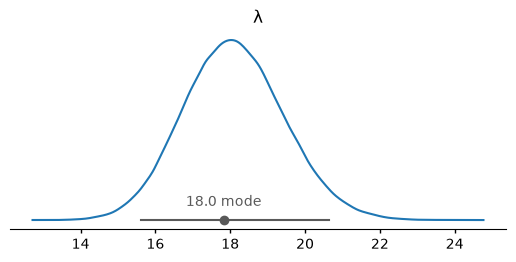

In [5]:
# scipy foloseste scale = 1 / beta
posterior = stats.gamma(a = alpha_post, scale = 1 / beta_post)
samples = posterior.rvs(size = 100000, random_state = 42)

dt = az.from_dict({"posterior": {"λ": samples[None, :]}})

hdi = az.hdi(samples, prob = 0.94)
print(f"HDI 94%: [{hdi[0]:.4f}, {hdi[1]:.4f}]")

az.plot_dist(dt, point_estimate = "mode", ci_kind = "hdi", ci_prob = 0.94)
plt.show()

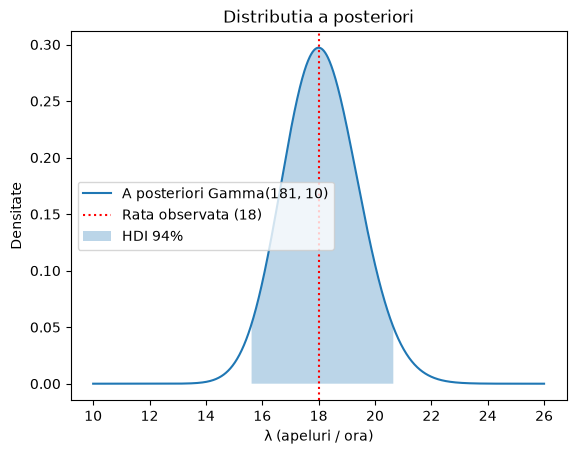

In [6]:
x = np.linspace(10, 26, 1000)

plt.plot(x, posterior.pdf(x), label = f"A posteriori Gamma({alpha_post}, {beta_post})")
plt.axvline(total_calls / n, color = "red", linestyle = ":", label = "Rata observata (18)")
plt.fill_between(x, posterior.pdf(x), where = (x >= hdi[0]) & (x <= hdi[1]), alpha = 0.3, label = "HDI 94%")
plt.xlabel("λ (apeluri / ora)")
plt.ylabel("Densitate")
plt.title("Distributia a posteriori")
plt.legend()
plt.show()

Distribuţia a posteriori este $\text{Gamma}(181, 10)$, cu cea mai probabilă valoare (modul) $\lambda = \frac{180}{10} = 18$ apeluri pe oră şi un interval HDI de 94% de aproximativ $[15.6, 20.7]$.

Voi mai adauga si alte distributii "priori".